In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split

# Cargar
ad_data = pd.read_csv('../datasets/advertising.xls')

# Seleccionar Variables (X) y Objetivo (y)
X = ad_data[['Daily Time Spent on Site', 'Age', 'Area Income', 'Daily Internet Usage', 'Male']]
y = ad_data['Clicked on Ad']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)  

In [2]:
from sklearn.linear_model import LogisticRegression

# Instanciar y Entrenar
logmodel = LogisticRegression(max_iter=1000)
logmodel.fit(X_train, y_train)

print("Modelo entrenado exitosamente.")

Modelo entrenado exitosamente.


In [3]:
from sklearn import metrics
from sklearn.metrics import classification_report, confusion_matrix

# Predecir clases (0 o 1)
predictions = logmodel.predict(X_test)

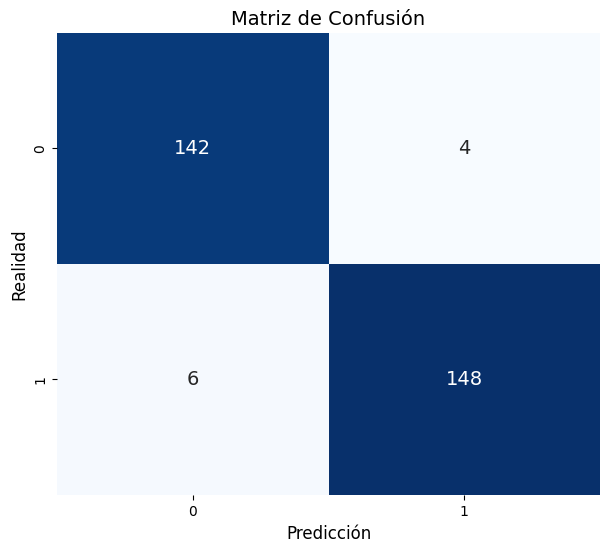

In [4]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Generar la matriz
cm = confusion_matrix(y_test, predictions)

# Graficar
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, annot_kws={'size':14})
plt.xlabel('Predicción', fontsize=12)
plt.ylabel('Realidad', fontsize=12)
plt.title('Matriz de Confusión', fontsize=14)
plt.show()

In [5]:
print("\n--- Reporte de Clasificación ---")
print(classification_report(y_test, predictions))


--- Reporte de Clasificación ---
              precision    recall  f1-score   support

           0       0.96      0.97      0.97       146
           1       0.97      0.96      0.97       154

    accuracy                           0.97       300
   macro avg       0.97      0.97      0.97       300
weighted avg       0.97      0.97      0.97       300



In [6]:
# Calcular AUC
logit_performance = round(metrics.roc_auc_score(y_test, predictions), 4)
print(f" (AUC): {logit_performance}")

 (AUC): 0.9668


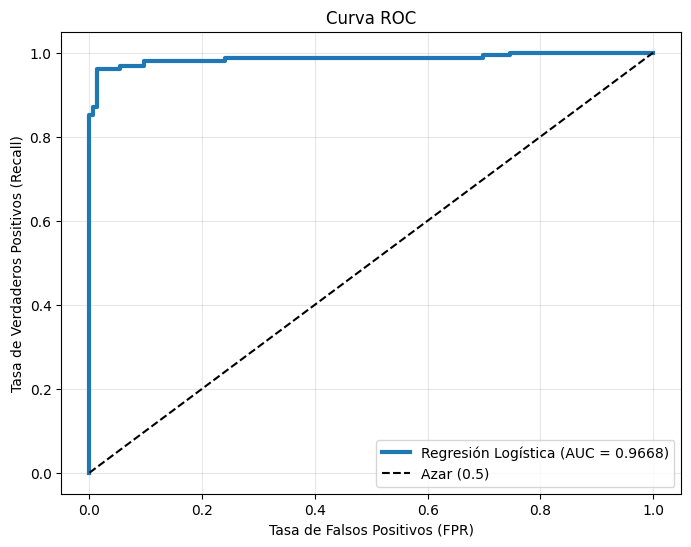

In [7]:
from sklearn.metrics import roc_curve, roc_auc_score

# Calcular probabilidades
y_prob = logmodel.predict_proba(X_test)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

auc = roc_auc_score(y_test, predictions)

# Graficar
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'Regresión Logística (AUC = {auc:.4f})', linewidth=3, color='#1f77b4')
plt.plot([0, 1], [0, 1], 'k--', label='Azar (0.5)')
plt.xlabel('Tasa de Falsos Positivos (FPR)')
plt.ylabel('Tasa de Verdaderos Positivos (Recall)')
plt.title('Curva ROC')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.show()

In [8]:
coeff_df = pd.DataFrame(logmodel.coef_[0], X.columns, columns=['Coeficiente'])
print(coeff_df)

                          Coeficiente
Daily Time Spent on Site    -0.191964
Age                          0.177573
Area Income                 -0.000148
Daily Internet Usage        -0.071801
Male                        -0.759926


C:\Users\magal\AppData\Local\Temp\ipykernel_31880\1106214684.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Coeficiente', y='Variable', data=coefs, palette='viridis')


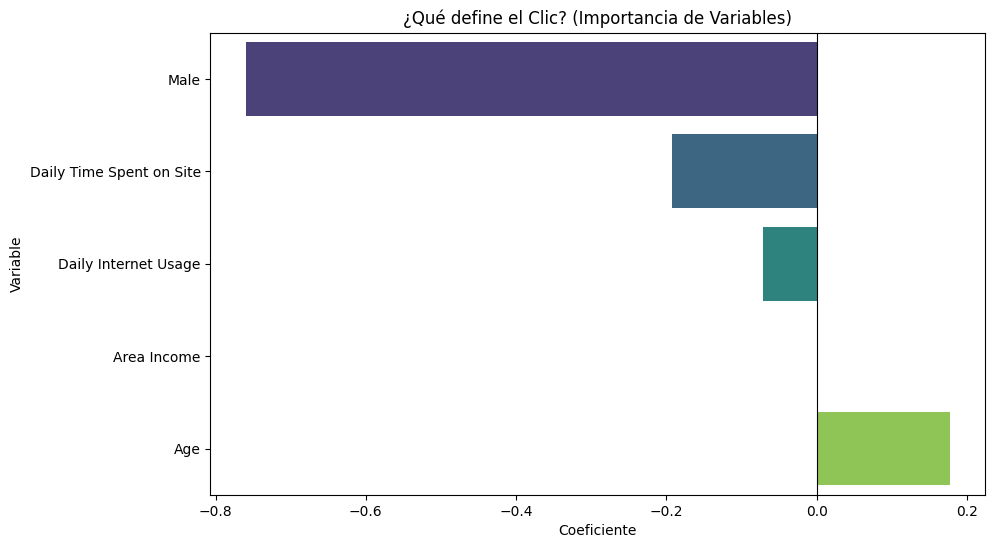

In [9]:
# Crear DataFrame de coeficientes
coefs = pd.DataFrame({'Variable': X.columns, 'Coeficiente': logmodel.coef_[0]})
coefs = coefs.sort_values(by='Coeficiente')

# Graficar
plt.figure(figsize=(10, 6))
sns.barplot(x='Coeficiente', y='Variable', data=coefs, palette='viridis')
plt.axvline(0, color='black', linewidth=0.8) # Línea central
plt.title('¿Qué define el Clic? (Importancia de Variables)')
plt.show()

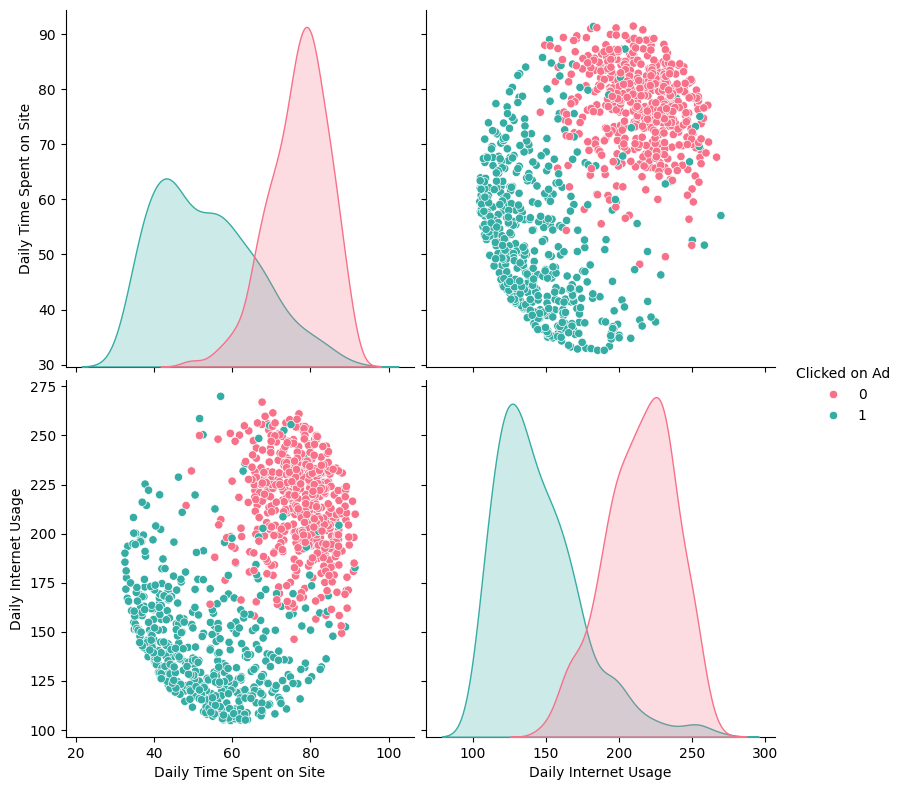

In [10]:
# Usamos 'hue' para pintar por la variable objetivo
sns.pairplot(ad_data, hue='Clicked on Ad', vars=['Daily Time Spent on Site', 'Daily Internet Usage'], palette='husl', height=4)
plt.show()

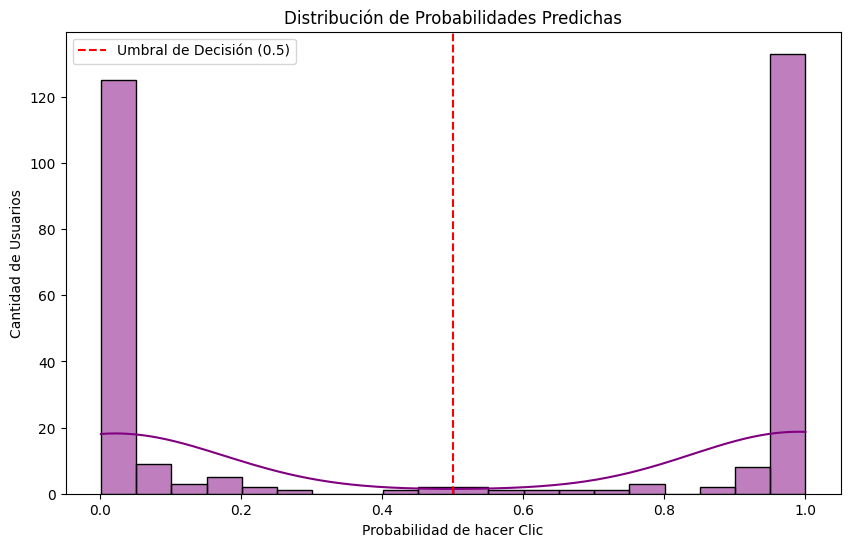

In [11]:
plt.figure(figsize=(10, 6))
sns.histplot(y_prob, bins=20, kde=True, color='purple')
plt.title('Distribución de Probabilidades Predichas')
plt.xlabel('Probabilidad de hacer Clic')
plt.ylabel('Cantidad de Usuarios')
plt.axvline(0.5, color='red', linestyle='--', label='Umbral de Decisión (0.5)')
plt.legend()
plt.show()

C:\Users\magal\AppData\Local\Temp\ipykernel_31880\3073074330.py:33: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  plt.axvline(corte_x, color='green', linestyle=':', label=f'Frontera ({float(corte_x):.1f} min)')


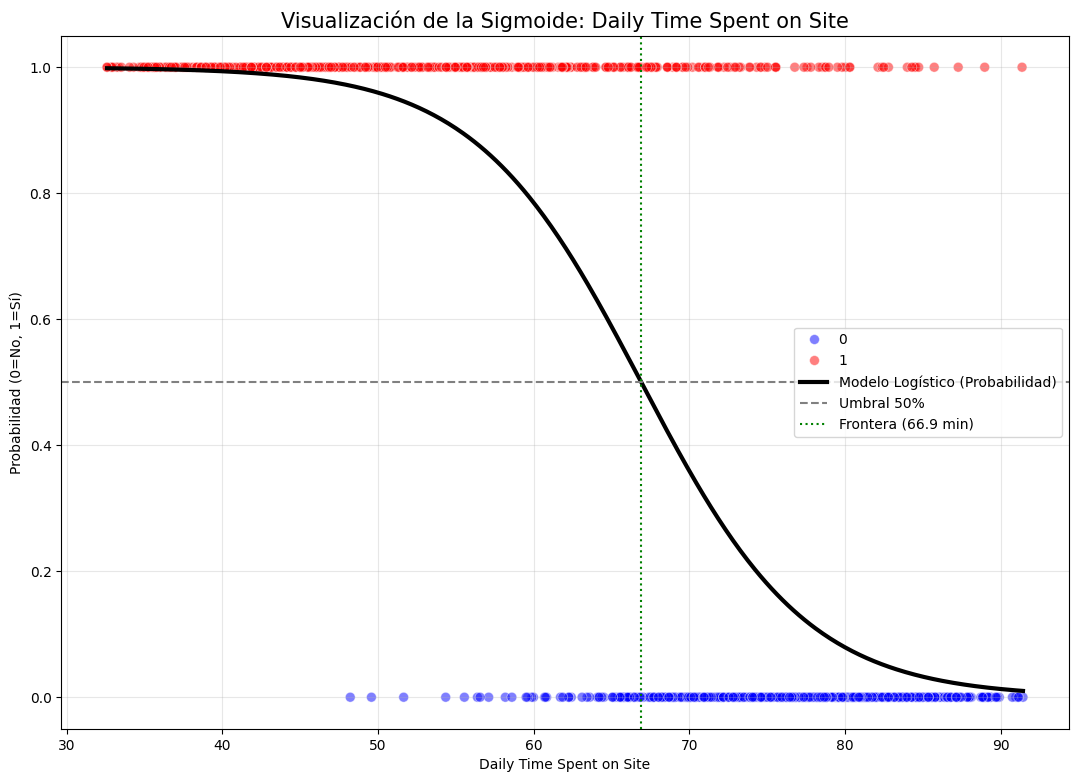

In [12]:
import numpy as np
from scipy.special import expit # Función sigmoide matemática

# --- Preparación para visualización 2D ---
# Elegimos la variable más fuerte: 'Daily Time Spent on Site'
feature_col = 'Daily Time Spent on Site'
X_simple = ad_data[[feature_col]]
y_simple = ad_data['Clicked on Ad']

# Entrenar modelo simple auxiliar (solo para este gráfico)
model_viz = LogisticRegression()
model_viz.fit(X_simple, y_simple)

# Generar puntos para la línea suave
x_range = np.linspace(X_simple.min(), X_simple.max(), 500)
y_sigmoid = expit(x_range * model_viz.coef_[0][0] + model_viz.intercept_[0])

# --- Graficar ---
plt.figure(figsize=(13, 9))

# A) Puntos Reales
sns.scatterplot(x=feature_col, y='Clicked on Ad', data=ad_data, 
                hue='Clicked on Ad', palette={0: 'blue', 1: 'red'}, 
                s=50, alpha=0.5)

# B) Curva Sigmoide
plt.plot(x_range, y_sigmoid, color='black', linewidth=3, label='Modelo Logístico (Probabilidad)')

# C) Líneas de referencia
plt.axhline(0.5, color='gray', linestyle='--', label='Umbral 50%')
# Calcular punto de corte visual
corte_x = x_range[np.abs(y_sigmoid - 0.5).argmin()]
plt.axvline(corte_x, color='green', linestyle=':', label=f'Frontera ({float(corte_x):.1f} min)')

plt.title(f'Visualización de la Sigmoide: {feature_col}', fontsize=15)
plt.ylabel('Probabilidad (0=No, 1=Sí)')
plt.legend(loc='center right')
plt.grid(True, alpha=0.3)
plt.show()